In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats

In [2]:
df = pd.read_excel('data.xlsx', sheet_name=None)
df_users = df['Пользователи']
df_payment = df['Платежи']

In [3]:
df_users.head()

,user_id,group,age,city,device_type
0,1001,A,31,Москва,ios
1,1002,A,31,Москва,ios
2,1003,A,25,Москва,android
3,1004,A,20,Москва,ios
4,1005,A,34,Москва,ios


In [4]:
df_payment.head()

,payment_id,user_id,group,step1_opened,step2_entered,step3_confirmed,step4_success
0,5001,1001.0,A,2024-04-16 06:06:00,2024-04-16 06:10:00,NaT,NaT
1,5002,1002.0,A,2024-04-12 07:38:00,2024-04-12 07:41:00,NaT,NaT
2,5003,1003.0,A,2024-04-26 20:03:00,2024-04-26 20:07:00,NaT,NaT
3,5004,1004.0,A,2024-04-09 16:02:00,NaT,NaT,NaT
4,5005,1004.0,A,2024-04-04 03:46:00,2024-04-04 03:54:00,2024-04-04 03:57:00,2024-04-04 04:02:00


In [5]:
df_users.isna().sum()

user_id        0
group          1
age            0
city           1
device_type    0
dtype: int64

In [6]:
df_payment.isna().sum()

payment_id            0
user_id               1
group                 0
step1_opened          0
step2_entered       405
step3_confirmed     942
step4_success      1139
dtype: int64

In [7]:
df_users.describe(include='all')

,user_id,group,age,city,device_type
count,1504.000000,1503,1504.000000,1503,1504
unique,NaN,2,NaN,3,2
top,NaN,A,NaN,Москва,android
freq,NaN,752,NaN,595,777
mean,1769.787234,NaN,32.745346,NaN,NaN
std,571.592080,NaN,8.410915,NaN,NaN
min,1001.000000,NaN,-5.000000,NaN,NaN
25%,1376.750000,NaN,27.000000,NaN,NaN
50%,1752.500000,NaN,33.000000,NaN,NaN
75%,2128.250000,NaN,38.000000,NaN,NaN


In [8]:
df_payment.describe(include='all')

,payment_id,user_id,group,step1_opened,step2_entered,step3_confirmed,step4_success
count,2661.000000,2660.000000,2661,2661,2256,1719,1522
unique,NaN,NaN,2,NaN,NaN,NaN,NaN
top,NaN,NaN,B,NaN,NaN,NaN,NaN
freq,NaN,NaN,1352,NaN,NaN,NaN,NaN
mean,6433.978579,1760.884211,NaN,2024-04-15 17:56:46.854566,2024-04-15 14:21:25.904255,2024-04-15 13:37:05.375218,2024-04-15 12:22:53.534822
min,5001.000000,1001.000000,NaN,2024-04-01 00:19:00,2024-04-01 00:23:00,2024-04-01 00:29:00,2024-04-01 00:33:00
25%,5666.000000,1388.000000,NaN,2024-04-08 01:30:00,2024-04-07 22:25:45,2024-04-07 19:01:00,2024-04-07 22:22:00
50%,6331.000000,1762.500000,NaN,2024-04-15 15:30:00,2024-04-15 05:12:30,2024-04-15 05:23:00,2024-04-14 23:01:00
75%,6996.000000,2135.250000,NaN,2024-04-23 13:25:00,2024-04-23 12:43:00,2024-04-23 14:28:00,2024-04-23 11:49:30
max,99003.000000,9004.000000,NaN,2024-04-30 23:17:00,2024-04-30 23:20:00,2024-04-30 23:25:00,2024-04-30 23:30:00


In [9]:
df_users['city'] = df_users['city'].fillna(df_users['city'].mode()[0])
df_users = df_users.dropna()
df_payment = df_payment.dropna(subset=['user_id'])


In [10]:
print(df_users['age'].sort_values())

1501     -5
686      20
685      20
3        20
891      20
       ... 
1480     57
459      58
817      60
68       60
1502    150
Name: age, Length: 1503, dtype: int64


In [11]:
df_users.iloc[[1501, 1500]]

,user_id,group,age,city,device_type
1502,9003,B,150,Регион,ios
1501,9002,A,-5,СПб,android


In [12]:
df_users.loc[df_users['user_id'] == 9003, 'age'] = pd.NA
df_users.loc[df_users['user_id'] == 9002, 'age'] = pd.NA
df_users['age'] = df_users['age'].fillna(df_users['age'].median())

In [13]:
print(df_users['age'].sort_values())

1483    20.0
34      20.0
42      20.0
1224    20.0
23      20.0
        ... 
615     56.0
1480    57.0
459     58.0
817     60.0
68      60.0
Name: age, Length: 1503, dtype: float64


In [14]:
df_users['age'].describe()

count    1503.000000
mean       32.697937
std         7.787579
min        20.000000
25%        27.000000
50%        33.000000
75%        38.000000
max        60.000000
Name: age, dtype: float64

In [15]:
df_payment['user_id'].value_counts()

user_id
1036.0    4
1045.0    4
1109.0    4
1132.0    4
1154.0    4
         ..
2496.0    1
2497.0    1
2498.0    1
2500.0    1
9004.0    1
Name: count, Length: 1501, dtype: int64

In [16]:
df_users['group'].value_counts()

group
A    752
B    751
Name: count, dtype: int64

In [17]:
df_payment['group'].value_counts()

group
B    1352
A    1308
Name: count, dtype: int64

In [18]:
df_users['device_type'].value_counts()

device_type
android    777
ios        726
Name: count, dtype: int64

In [19]:
df_users['city'].value_counts()

city
Москва    595
Регион    514
СПб       394
Name: count, dtype: int64

In [20]:
n_payments = df_payment.groupby(by=['user_id']).agg({'step1_opened': 'count', 'step4_success': 'count'})

In [21]:
df_users = pd.merge(df_users, n_payments, on='user_id')
df_users['conversion'] = df_users['step4_success']/df_users['step1_opened']
df_users

,user_id,group,age,city,device_type,step1_opened,step4_success,conversion
0,1001,A,31.0,Москва,ios,1,0,0.000000
1,1002,A,31.0,Москва,ios,1,0,0.000000
2,1003,A,25.0,Москва,android,1,0,0.000000
3,1004,A,20.0,Москва,ios,3,2,0.666667
4,1005,A,34.0,Москва,ios,2,1,0.500000
...,...,...,...,...,...,...,...,...
1496,2497,B,33.0,Москва,android,1,0,0.000000
1497,2498,B,28.0,СПб,ios,1,1,1.000000
1498,2499,B,42.0,Москва,ios,3,3,1.000000
1499,2500,B,39.0,Москва,ios,1,0,0.000000


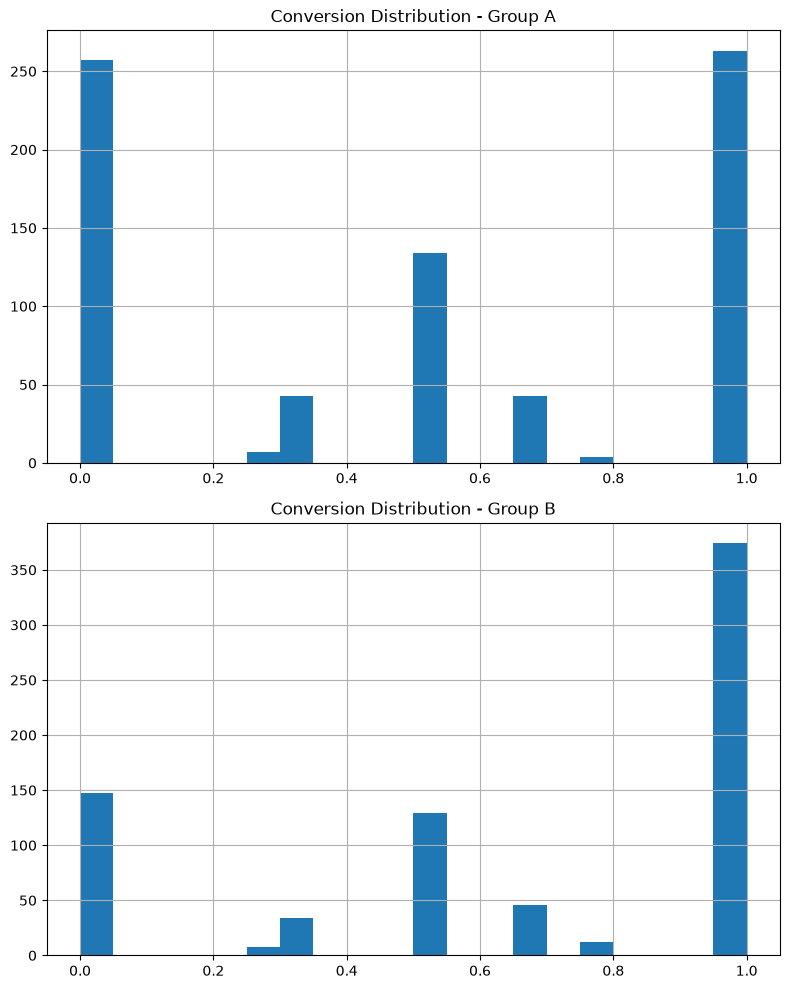

In [22]:
fig, axes = plt.subplots(2, 1, figsize=(8, 10))


df_users.loc[df_users['group'] == 'A', 'conversion'].hist(ax=axes[0], bins=20)
axes[0].set_title('Conversion Distribution - Group A')


df_users.loc[df_users['group'] == 'B', 'conversion'].hist(ax=axes[1], bins=20)
axes[1].set_title('Conversion Distribution - Group B')

plt.tight_layout()
plt.show()

In [23]:

def delta_method_stats(sub: pd.DataFrame, n_col='step1_opened', y_col='step4_success'):
    n = len(sub)
    mean_N = sub[n_col].mean()
    mean_Y = sub[y_col].mean()
    var_N = sub[n_col].var(ddof=1)
    var_Y = sub[y_col].var(ddof=1)
    cov_NY = sub[[n_col, y_col]].cov().iloc[0, 1]

    R = mean_Y / mean_N
    var_R = (1 / (n * mean_N**2)) * (var_Y - 2 * R * cov_NY + R**2 * var_N)

    return R, var_R, n


stats_a = delta_method_stats(df_users[df_users['group'] == 'A'])
stats_b = delta_method_stats(df_users[df_users['group'] == 'B'])

R_a, var_a, n_a = stats_a
R_b, var_b, n_b = stats_b

diff = R_b - R_a
se_diff = np.sqrt(var_a + var_b)

z = diff / se_diff
p_value = 2 * (1 - stats.norm.cdf(abs(z)))
ci_low, ci_high = diff - 1.96 * se_diff, diff + 1.96 * se_diff

print(f"Conversion A: {R_a:.4f} (n={n_a})")
print(f"Conversion B: {R_b:.4f} (n={n_b})")
print(f"Diff (B - A): {diff:.4f}")
print(f"95% CI: [{ci_low:.4f}, {ci_high:.4f}]")
print(f"Z = {z:.3f}, p-value = {p_value:.4f}")

Conversion A: 0.4981 (n=751)
Conversion B: 0.6440 (n=750)
Diff (B - A): 0.1459
95% CI: [0.1088, 0.1829]
Z = 7.720, p-value = 0.0000


In [24]:
# 1. Prepare step flags at payment level
for s in ['step1_opened', 'step2_entered', 'step3_confirmed', 'step4_success']:
    df_payment[s + '_flag'] = df_payment[s].notna().astype(int)

# 2. Aggregate step counts per user
user_steps = df_payment.groupby('user_id').agg(
    s1=('step1_opened_flag', 'sum'),
    s2=('step2_entered_flag', 'sum'),
    s3=('step3_confirmed_flag', 'sum'),
    s4=('step4_success_flag', 'sum')
).reset_index()

df_funnel = pd.merge(df_users, user_steps, on='user_id')

# 3. Delta Method for Step Transitions
def evaluate_funnel_step(df_sub, step_name, n_col, y_col):
    sub_a = df_sub[df_sub['group'] == 'A']
    sub_b = df_sub[df_sub['group'] == 'B']
    
    def dm_calc(sub):
        n = len(sub)
        mean_N = sub[n_col].mean()
        mean_Y = sub[y_col].mean()
        var_N = sub[n_col].var(ddof=1)
        var_Y = sub[y_col].var(ddof=1)
        cov_NY = sub[[n_col, y_col]].cov().iloc[0, 1]
        R = mean_Y / mean_N if mean_N > 0 else 0
        var_R = (1 / (n * mean_N**2)) * (var_Y - 2 * R * cov_NY + R**2 * var_N)
        return R, var_R, n
    
    ra, va, na = dm_calc(sub_a)
    rb, vb, nb = dm_calc(sub_b)
    diff = rb - ra
    rel_diff = (diff / ra) * 100
    se = np.sqrt(va + vb)
    z = diff / se
    p_val = 2 * (1 - stats.norm.cdf(abs(z)))
    ci_low, ci_high = diff - 1.96 * se, diff + 1.96 * se
    
    return {
        'Step': step_name,
        'Conv A': f"{ra:.2%}",
        'Conv B': f"{rb:.2%}",
        'Abs Diff (B-A)': f"{diff:+.2%}",
        'Relative Uplift': f"{rel_diff:+.2f}%",
        '95% CI': f"[{ci_low:+.4f}, {ci_high:+.4f}]",
        'Z-score': round(z, 3),
        'p-value': f"{p_val:.4e}"
    }

steps = [
    ('Step 1 -> 2 (Open -> Enter)', 's1', 's2'),
    ('Step 2 -> 3 (Enter -> Confirm)', 's2', 's3'),
    ('Step 3 -> 4 (Confirm -> Success)', 's3', 's4'),
    ('Overall: Step 1 -> 4', 's1', 's4')
]

results = [evaluate_funnel_step(df_funnel, name, n_col, y_col) for name, n_col, y_col in steps]
funnel_df = pd.DataFrame(results)
display(funnel_df)


,Step,Conv A,Conv B,Abs Diff (B-A),Relative Uplift,95% CI,Z-score,p-value
0,Step 1 -> 2 (Open -> Enter),81.13%,88.38%,+7.25%,+8.93%,"[+0.0445, +0.1004]",5.084,3.6985e-07
1,Step 2 -> 3 (Enter -> Confirm),71.47%,80.40%,+8.93%,+12.50%,"[+0.0551, +0.1236]",5.111,3.2070e-07
2,Step 3 -> 4 (Confirm -> Success),85.90%,90.62%,+4.72%,+5.50%,"[+0.0162, +0.0782]",2.987,2.8184e-03
3,Overall: Step 1 -> 4,49.81%,64.40%,+14.59%,+29.29%,"[+0.1088, +0.1829]",7.720,1.1768e-14


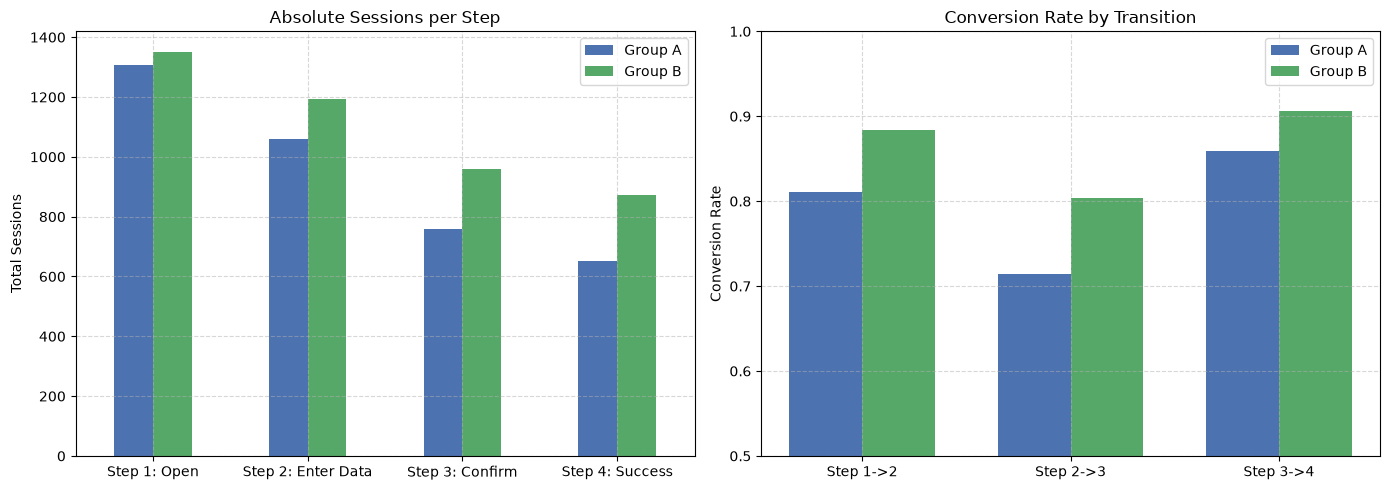

In [25]:
# Funnel visualization
funnel_counts = df_payment.groupby('group')[
    ['step1_opened_flag', 'step2_entered_flag', 'step3_confirmed_flag', 'step4_success_flag']
].sum().T

funnel_counts.columns = ['Group A', 'Group B']
funnel_counts.index = ['Step 1: Open', 'Step 2: Enter Data', 'Step 3: Confirm', 'Step 4: Success']

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Absolute volume
funnel_counts.plot(kind='bar', ax=ax[0], rot=0, color=['#4C72B0', '#55A868'])
ax[0].set_title('Absolute Sessions per Step')
ax[0].set_ylabel('Total Sessions')
ax[0].grid(True, linestyle='--', alpha=0.5)

# Step-to-Step Conversion Rates
step_conv_a = [1061/1308, 758/1061, 651/758]
step_conv_b = [1195/1352, 961/1195, 871/961]
step_labels = ['Step 1->2', 'Step 2->3', 'Step 3->4']

x = np.arange(len(step_labels))
width = 0.35

ax[1].bar(x - width/2, step_conv_a, width, label='Group A', color='#4C72B0')
ax[1].bar(x + width/2, step_conv_b, width, label='Group B', color='#55A868')
ax[1].set_xticks(x)
ax[1].set_xticklabels(step_labels)
ax[1].set_ylim(0.5, 1.0)
ax[1].set_ylabel('Conversion Rate')
ax[1].set_title('Conversion Rate by Transition')
ax[1].legend()
ax[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


In [26]:
import pandas as pd
import numpy as np
import statsmodels.formula.api as smf

# 1. Prepare payment-level data with user attributes
df_payment_user = pd.merge(
    df_payment, 
    df_users[['user_id', 'age', 'city', 'device_type']], 
    on='user_id'
)
df_payment_user['success'] = df_payment_user['step4_success'].notna().astype(int)

# 2. Fit Multiple Logistic Regression with Cluster-Robust Standard Errors
# Reference categories: Group = 'A', City = 'Москва', Device = 'android'
formula = "success ~ C(group, Treatment('A')) + C(city, Treatment('Москва')) + C(device_type, Treatment('android')) + age"

logit_model = smf.logit(formula, data=df_payment_user).fit(
    cov_type='cluster', 
    cov_kwds={'groups': df_payment_user['user_id']}
)

# 3. Calculate Odds Ratios and 95% Confidence Intervals
results_table = pd.DataFrame({
    'Log-Odds (Coef)': logit_model.params,
    'Std Error': logit_model.bse,
    'z-score': logit_model.tvalues,
    'p-value': logit_model.pvalues,
    'Odds Ratio (OR)': np.exp(logit_model.params),
    'OR 95% CI Lower': np.exp(logit_model.conf_int()[0]),
    'OR 95% CI Upper': np.exp(logit_model.conf_int()[1])
})

display(results_table.round(4))


Optimization terminated successfully.
         Current function value: 0.670323
         Iterations 4


,Log-Odds (Coef),Std Error,z-score,p-value,Odds Ratio (OR),OR 95% CI Lower,OR 95% CI Upper
Intercept,0.2438,0.1787,1.3641,0.1726,1.2760,0.8990,1.8112
"C(group, Treatment('A'))[T.B]",0.6018,0.0793,7.5930,0.0000,1.8254,1.5628,2.1322
"C(city, Treatment('Москва'))[T.Регион]",0.0093,0.0929,0.1002,0.9202,1.0094,0.8414,1.2109
"C(city, Treatment('Москва'))[T.СПб]",0.1573,0.0983,1.5996,0.1097,1.1703,0.9652,1.4190
"C(device_type, Treatment('android'))[T.ios]",0.0661,0.0792,0.8353,0.4035,1.0684,0.9148,1.2477
age,-0.0100,0.0049,-2.0604,0.0394,0.9900,0.9807,0.9995


<Axes: >

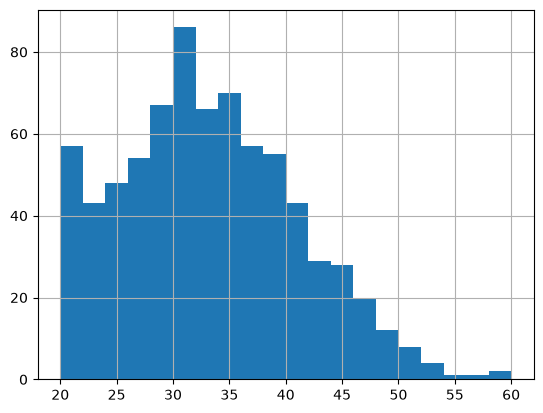

In [29]:
df_users.loc[df_users['group'] == 'A', 'age'].hist(bins=20)

<Axes: >

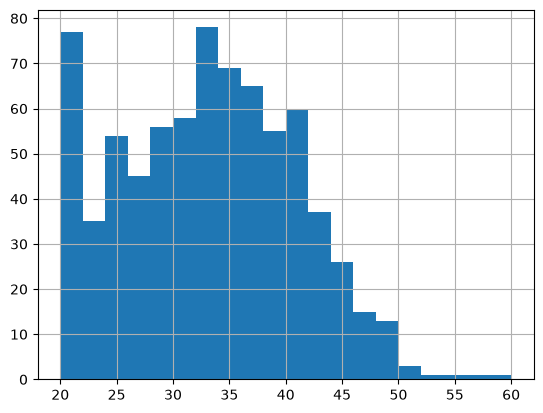

In [30]:
df_users.loc[df_users['group'] == 'B', 'age'].hist(bins=20)

In [41]:
from scipy import stats

age1 = df_users.loc[df_users['group'] == 'A', 'age']
age2 = df_users.loc[df_users['group'] == 'B', 'age']

ks_statistic, p_value = stats.ks_2samp(age1, age2)
print(f"KS statistic: {ks_statistic}")
print(f"P-value: {p_value}")


KS statistic: 0.03936972924988913
P-value: 0.5845068347136164


In [44]:
print(young1 := df_users.query('group == "A" and age == 20').shape[0])
print(young2 := df_users.query('group == "B" and age == 20').shape[0])

43
55


In [47]:
old1 = df_users.query('group == "A"').shape[0] - young1
old2 = df_users.query('group == "A"').shape[0] - young2

table = [[young1, old1],
         [young2, old2]]

fisher_stat, p_value = stats.fisher_exact(table, alternative='two-sided')

print(f"Odds Ratio: {fisher_stat:.3f}")
print(f"P-value: {p_value:.4f}")


Odds Ratio: 0.769
P-value: 0.2503
